1. **Introduction**


This project is about exploring an insurance dataset using Exploratory Data Analysis (EDA). The main aim is to understand the data, find patterns, spot unusual values, and study how different factors like age, BMI, smoking habits, and insurance charges are related. EDA helps us better understand the data before using it for further analysis or modeling.

2. **What is EDA**

Exploratory Data Analysis (EDA) is a method used to study and understand a dataset. It involves using basic statistics and graphs to summarize the data. EDA helps us see how the data is spread, find unusual values, and understand relationships between different variables.

3. **Description of Dataset**


*   Age: Age of the individual
*   Sex: Gender (male/female)
*   BMI: Body Mass Index, indicating body fat
*   Children: Number of dependents
*   Smoker: Whether the individual smokes or not
*   Region: Residential area
*   Charges: Medical insurance cost (target variable)










In [1]:
import pandas as pd
df = pd.read_csv('Insurance.csv')

In [2]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df.head()
df.shape
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


1. **Univariate Analysis**

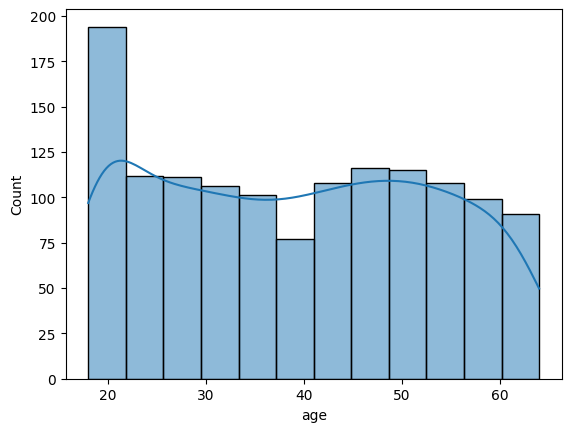

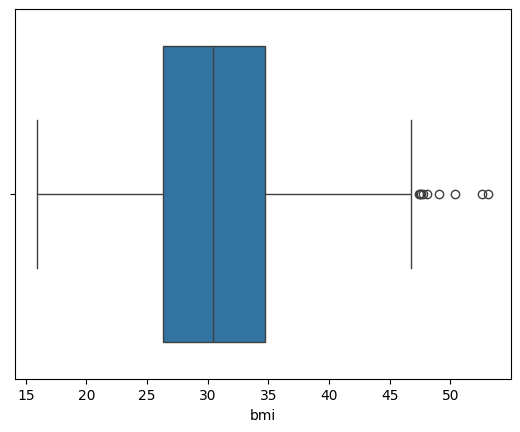

In [5]:
sns.histplot(df['age'], kde=True)
plt.show()
sns.boxplot(x=df['bmi'])
plt.show()

**Categorical Data**

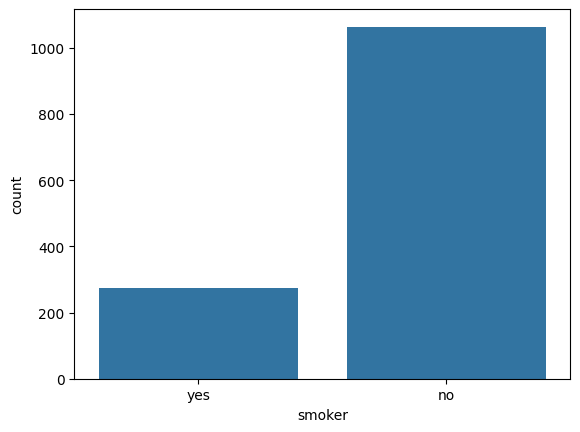

In [6]:
sns.countplot(x='smoker', data=df)
plt.show()

**Relationships**

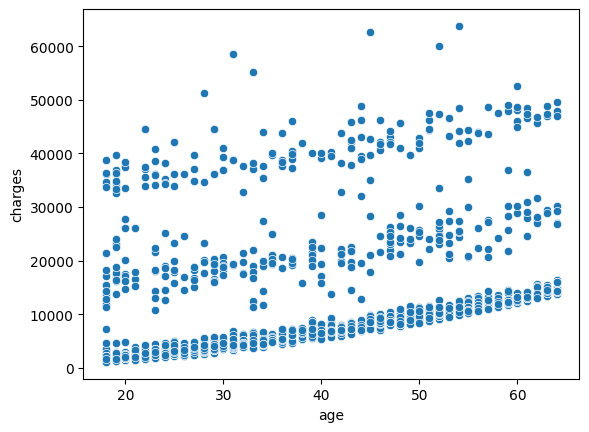

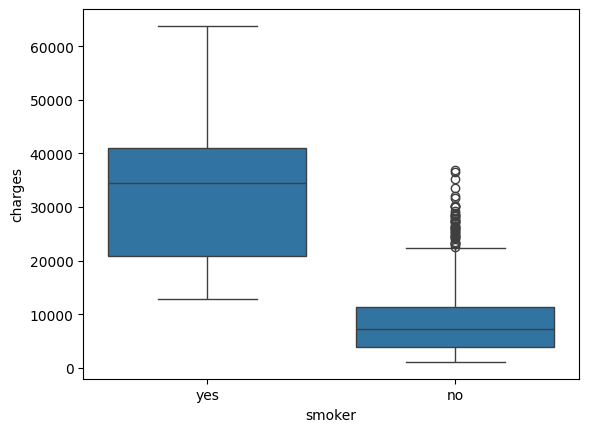

In [7]:
sns.scatterplot(x='age', y='charges', data=df)
plt.show()

sns.boxplot(x='smoker', y='charges', data=df)
plt.show()

2. **Bivariate Analysis**

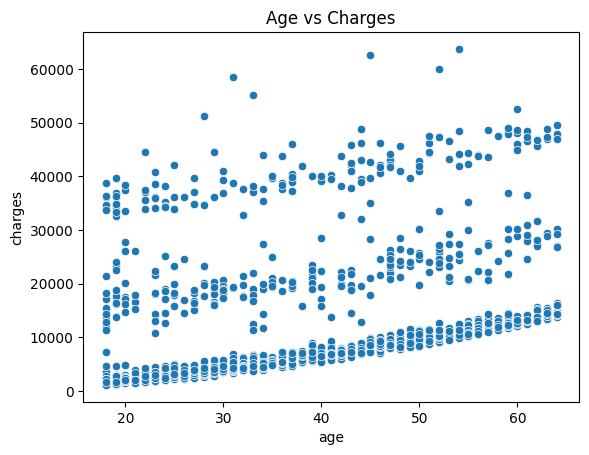

In [8]:
# Age vs Charges
plt.figure()
sns.scatterplot(x='age', y='charges', data=df)
plt.title('Age vs Charges')
plt.show()

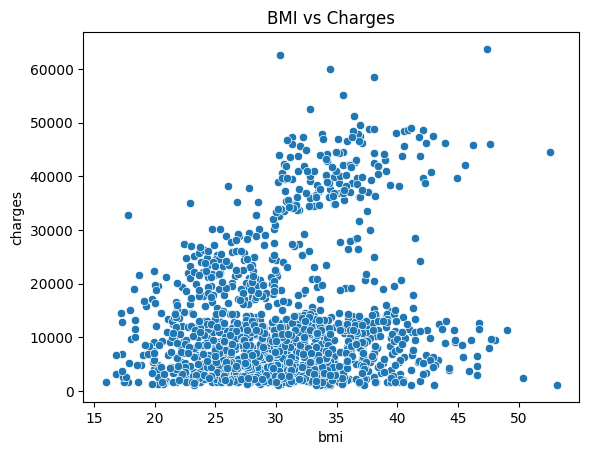

In [9]:
# BMI vs Charges
plt.figure()
sns.scatterplot(x='bmi', y='charges', data=df)
plt.title('BMI vs Charges')
plt.show()

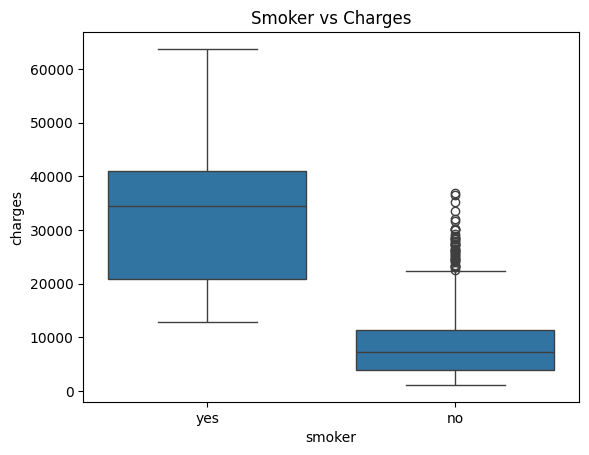

In [10]:
# Smoker vs Charges (IMPORTANT)
plt.figure()
sns.boxplot(x='smoker', y='charges', data=df)
plt.title('Smoker vs Charges')
plt.show()

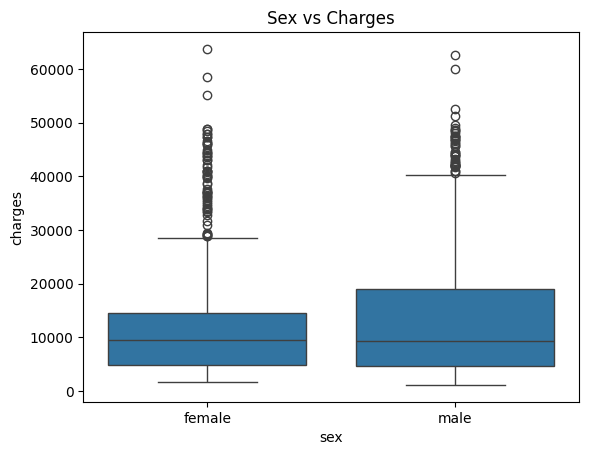

In [11]:
# Sex vs Charges
plt.figure()
sns.boxplot(x='sex', y='charges', data=df)
plt.title('Sex vs Charges')
plt.show()

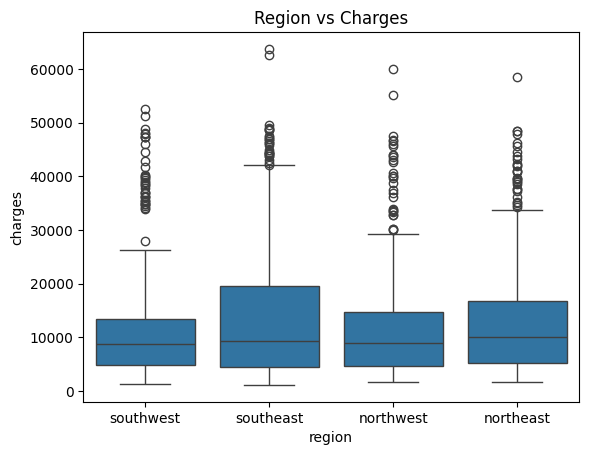

In [12]:
# Region vs Charges
plt.figure()
sns.boxplot(x='region', y='charges', data=df)
plt.title('Region vs Charges')
plt.show()

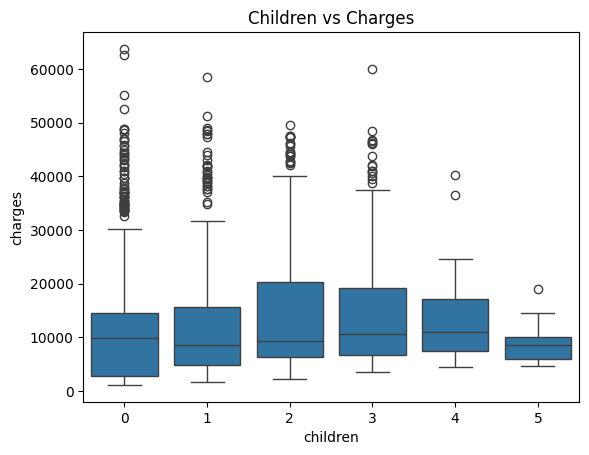

In [13]:
# Children vs Charges
plt.figure()
sns.boxplot(x='children', y='charges', data=df)
plt.title('Children vs Charges')
plt.show()

3. **Multivariate Analysis**

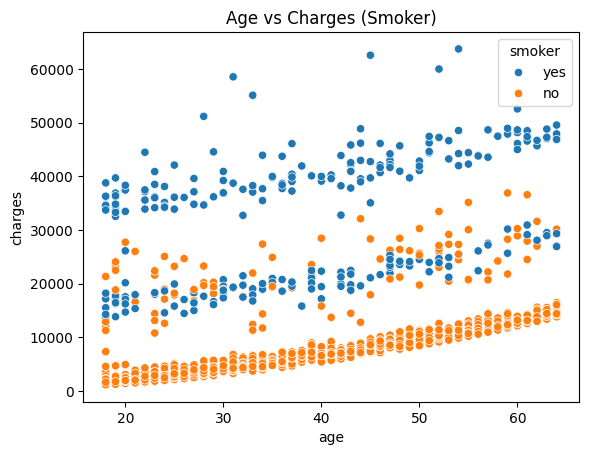

In [14]:
# Age vs Charges with smoker
plt.figure()
sns.scatterplot(x='age', y='charges', hue='smoker', data=df)
plt.title('Age vs Charges (Smoker)')
plt.show()

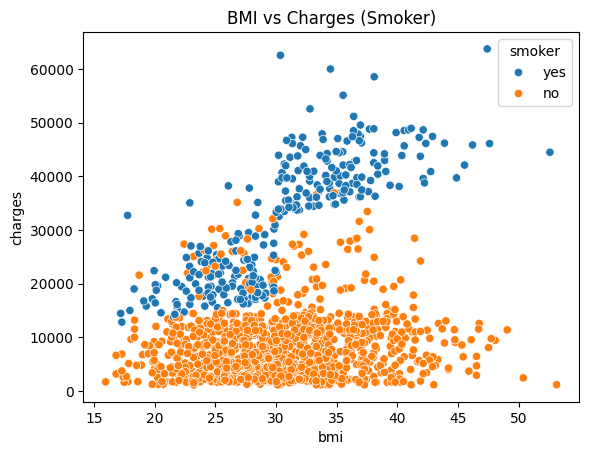

In [15]:
# BMI vs Charges with smoker
plt.figure()
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df)
plt.title('BMI vs Charges (Smoker)')
plt.show()

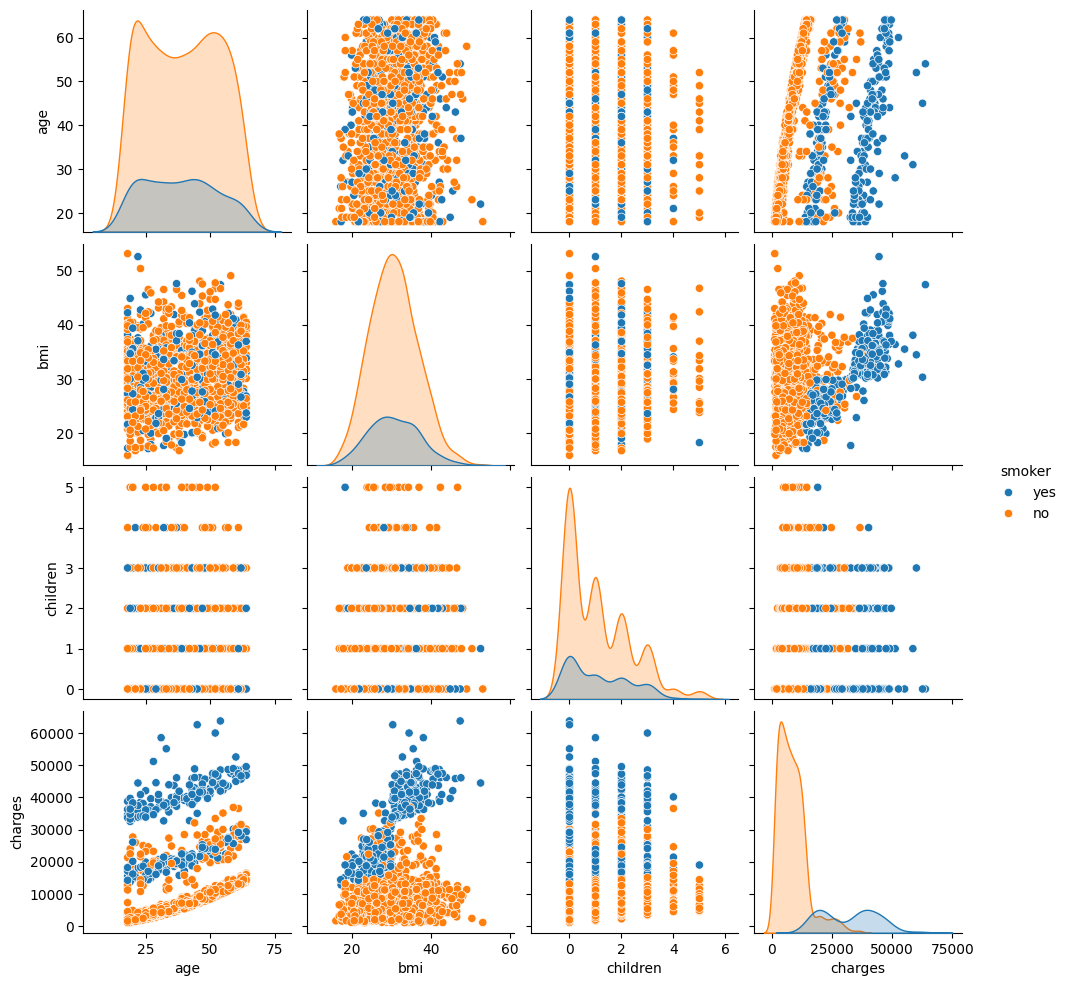

In [16]:
# Pairplot
sns.pairplot(df, hue='smoker')
plt.show()

4. **Outlier Detection**

In [17]:
Q1 = df['charges'].quantile(0.25)
Q3 = df['charges'].quantile(0.75)
IQR = Q3 - Q1

In [18]:
# Calculate lower and upper boundaries

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 4740.28715
Q3: 16639.912515
IQR: 11899.625365
Lower Bound: -13109.1508975
Upper Bound: 34489.350562499996


In [19]:
# Identify outliers

outliers = df[
    (df['charges'] < lower_bound) |
    (df['charges'] > upper_bound)
]

print("Total Outliers:", len(outliers))

print("\nOutlier Records:")
display(outliers)

Total Outliers: 139

Outlier Records:


,age,sex,bmi,children,smoker,region,charges
14,27,male,42.130,0,yes,southeast,39611.75770
19,30,male,35.300,0,yes,southwest,36837.46700
23,34,female,31.920,1,yes,northeast,37701.87680
29,31,male,36.300,2,yes,southwest,38711.00000
30,22,male,35.600,0,yes,southwest,35585.57600
...,...,...,...,...,...,...,...
1300,45,male,30.360,0,yes,southeast,62592.87309
1301,62,male,30.875,3,yes,northwest,46718.16325
1303,43,male,27.800,0,yes,southwest,37829.72420
1313,19,female,34.700,2,yes,southwest,36397.57600


In [20]:
# Calculate percentage of outliers

outlier_percentage = (
    len(outliers) / len(df)
) * 100

print("Percentage of Outliers:",
      round(outlier_percentage, 2), "%")

Percentage of Outliers: 10.39 %


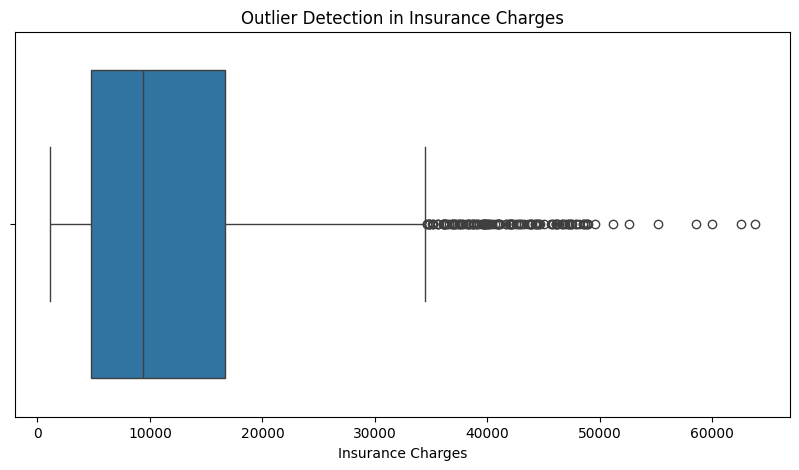

In [21]:
# Visualize insurance charges outliers

plt.figure(figsize=(10, 5))

sns.boxplot(x=df['charges'])

plt.title("Outlier Detection in Insurance Charges")
plt.xlabel("Insurance Charges")

plt.show()

5. **Feature Engineering**

In [22]:
# BMI Category
df['bmi_category'] = pd.cut(df['bmi'],
                           bins=[0,18.5,25,30,100],
                           labels=['Underweight','Normal','Overweight','Obese'])

# Age Group
df['age_group'] = pd.cut(df['age'],
                         bins=[18,30,45,60,100],
                         labels=['18-30','30-45','45-60','60+'])

6. **Analysis on New Features**

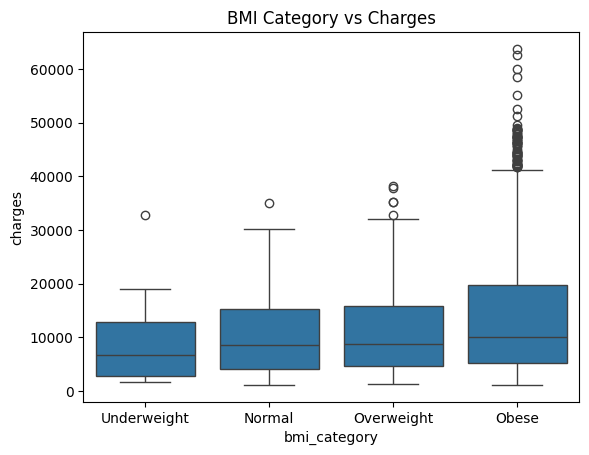

In [23]:
plt.figure()
sns.boxplot(x='bmi_category', y='charges', data=df)
plt.title('BMI Category vs Charges')
plt.show()

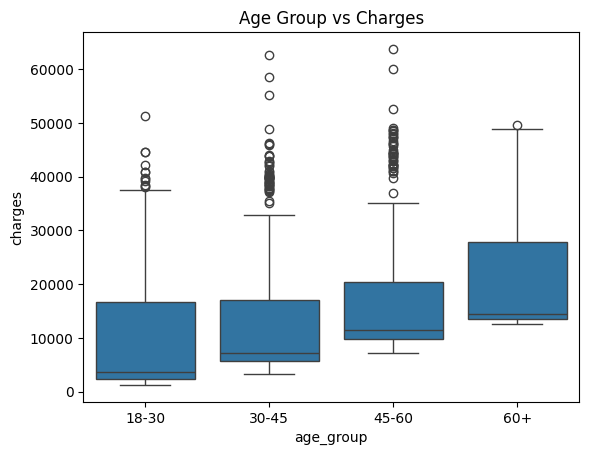

In [24]:
# Age Group vs Charges
plt.figure()
sns.boxplot(x='age_group', y='charges', data=df)
plt.title('Age Group vs Charges')
plt.show()

 7. **Key Insights**

In [25]:
print("\nAverage Charges by Smoker:")
print(df.groupby('smoker')['charges'].mean())

print("\nAverage Charges by BMI Category:")
print(df.groupby('bmi_category')['charges'].mean())

print("\nAverage Charges by Age Group:")
print(df.groupby('age_group')['charges'].mean())


Average Charges by Smoker:
smoker
no      8434.268298
yes    32050.231832
Name: charges, dtype: float64

Average Charges by BMI Category:
bmi_category
Underweight     8657.620652
Normal         10435.440719
Overweight     10997.803881
Obese          15560.926321
Name: charges, dtype: float64

Average Charges by Age Group:
age_group
18-30     9822.837599
30-45    12647.455654
45-60    16340.993846
60+      21063.163398
Name: charges, dtype: float64


/tmp/ipykernel_937/2321931495.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('bmi_category')['charges'].mean())
/tmp/ipykernel_937/2321931495.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('age_group')['charges'].mean())


8. **Summary**

In this project, we explored an insurance dataset using Exploratory Data Analysis (EDA) to understand how the data is organized. We used different methods like data cleaning, basic statistics, and graphs to study the data. Charts such as histograms, boxplots, and scatterplots helped us understand both numerical and categorical variables. This analysis helped us find patterns, detect unusual values, and understand how factors like age, BMI, smoking, and charges are related.

9. **Result**

From the analysis, we found some important results. Smoking has a big effect on insurance charges, as smokers pay much more than non-smokers. Age is also important because charges increase as people get older. People with higher BMI usually have higher medical costs. The number of children and region do not affect charges as much. Overall, EDA helped us understand the main factors that affect insurance costs.